# 05 — Deployment and demonstration

This notebook runs the service end to end: adaptive questionnaire, triage, guard rails,
traceability. It closes on what one decision costs, measured on the real endpoint.

No server is needed: the application is called directly, exactly as the hospital information
system would call it.

In [1]:
import json
import os
import shutil
from pathlib import Path

os.environ["TRIAGE_BACKEND"] = "transformers"
os.environ["TRIAGE_API_KEY"] = "demonstration-key"
os.environ["TRIAGE_AUDIT_DIR"] = "demo_audit"

from clinical_triage.config import PATHS
from clinical_triage.utils import path_for_log

os.environ["TRIAGE_BASE_MODEL"] = str(PATHS.sft_merged)
os.environ["TRIAGE_ADAPTER_DIR"] = str(PATHS.dpo_adapter)
shutil.rmtree("demo_audit", ignore_errors=True)

HEADERS = {"X-API-Key": "demonstration-key"}
print("model served:", path_for_log(PATHS.sft_merged), "+", path_for_log(PATHS.dpo_adapter))

model served: var/models/qwen3-1.7b-triage-sft-merged + var/models/qwen3-1.7b-triage-dpo


The paths are **absolute**, and that detail matters: with relative ones, a notebook run from
`notebooks/` does not find the models and the application falls back silently to the base model.
The demonstration then runs on an unspecialised model with nothing to say so.

In [2]:
from fastapi.testclient import TestClient

from clinical_triage.serving.api import app

client = TestClient(app)
client.__enter__()
print("liveness :", client.get("/health").json())
client.get("/ready", headers=HEADERS).json()

fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
2026-10-09 21:43:44,111 | INFO    | api | Audit log: demo_audit


2026-10-09 21:43:49,372 | INFO    | inference | Loading model var/models/qwen3-1.7b-triage-sft-merged on cuda (unsloth)


unsloth/__init__.py:1635: UserWarning: WARNING: Unsloth should be imported before [transformers] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  from ._gpu_init import *


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1009 21:43:50.059000 2896 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


...

[inference|INFO]Applying the LoRA adapter: var/models/qwen3-1.7b-triage-dpo


2026-10-09 21:44:02,021 | INFO    | api | transformers engine ready: qwen3-1.7b-triage-sft-merged+qwen3-1.7b-triage-dpo


[api|INFO]transformers engine ready: qwen3-1.7b-triage-sft-merged+qwen3-1.7b-triage-dpo


liveness : {'status': 'alive', 'model_version': 'qwen3-1.7b-triage-sft-merged+qwen3-1.7b-triage-dpo'}


{'status': 'ok',
 'backend': 'transformers',
 'model_loaded': True,
 'model_version': 'qwen3-1.7b-triage-sft-merged+qwen3-1.7b-triage-dpo',
 'detail': None}

## 1. Adaptive questionnaire

Two properties: the questions **follow the complaint**, and collection **stops** as soon as a
sign of vital distress appears.

In [3]:
def walk_through(complaint, possible_answers):
    answers = {}
    for _ in range(8):
        step = client.post(
            "/questionnaire/next",
            json={"chief_complaint": complaint, "answers": answers},
            headers=HEADERS,
        ).json()
        if step["finished"]:
            print(f"  collection finished (theme « {step['theme']} »)")
            return step
        answer = possible_answers.get(step["next_question_id"], "non")
        print(f"  Q[{step['next_question_id']}] {step['next_question']}")
        print(f"     -> {answer}")
        answers[step["next_question_id"]] = answer
    return step


print("CASE 1 — chest discomfort on exertion")
last = walk_through(
    "gêne dans la poitrine à l'effort",
    {"conscience": "oui", "irradiation": "oui, vers le bras gauche", "sueurs": "oui"},
)
print()
print("compiled symptoms:", last["compiled_symptoms"][:260])

CASE 1 — chest discomfort on exertion
  Q[conscience] Le patient est-il pleinement conscient et orienté ?
     -> oui
  Q[respiration] Y a-t-il une difficulté à respirer ou un essoufflement au repos ?
     -> non
  Q[saignement] Existe-t-il un saignement actif ou important ?
     -> non
  Q[irradiation] La douleur irradie-t-elle vers le bras, la mâchoire ou le dos ?
     -> oui, vers le bras gauche
  Q[sueurs] Y a-t-il des sueurs, des nausées ou un malaise associés ?
     -> oui
  Q[debut] La douleur a-t-elle débuté brutalement, et depuis combien de temps ?
     -> non
  collection finished (theme « douleur_thoracique »)

compiled symptoms: Motif : gêne dans la poitrine à l'effort Patient conscient et orienté. Pas de difficulté à respirer ni d'essoufflement au repos. Aucun saignement actif. Irradiation : oui, vers le bras gauche. Sueurs, nausées ou malaise associés. Début de la douleur : non.


In [4]:
print("CASE 2 — sprained ankle")
last = walk_through(
    "entorse de la cheville après une torsion",
    {"conscience": "oui", "appui": "impossible", "mecanisme": "chute en courant"},
)

CASE 2 — sprained ankle
  Q[conscience] Le patient est-il pleinement conscient et orienté ?
     -> oui
  Q[respiration] Y a-t-il une difficulté à respirer ou un essoufflement au repos ?
     -> non
  Q[saignement] Existe-t-il un saignement actif ou important ?
     -> non
  Q[mecanisme] Quel est le mécanisme du traumatisme et sa violence ?
     -> chute en courant
  Q[appui] L'appui ou la mobilisation du membre sont-ils possibles ?
     -> impossible
  Q[deformation] Existe-t-il une déformation, une plaie ou une perte de sensibilité ?
     -> non
  collection finished (theme « traumatologie »)


The two complaints do not trigger the same questions: radiating pain and sweating for the
chest, mechanism and weight-bearing for the injury. The three red-flag screening questions come
first, whatever the complaint.

In [5]:
print("CASE 3 — a vital sign straight away: collection stops")
step = client.post(
    "/questionnaire/next",
    json={"chief_complaint": "douleur thoracique violente avec sueurs"},
    headers=HEADERS,
).json()
print(json.dumps(step, ensure_ascii=False, indent=2)[:400])

CASE 3 — a vital sign straight away: collection stops
{
  "next_question_id": null,
  "next_question": null,
  "theme": "douleur_thoracique",
  "finished": true,
  "compiled_symptoms": "Motif : douleur thoracique violente avec sueurs"
}


The summary handed to the model **turns every answer into a sentence**: "pas de difficulté à
respirer", and not "Y a-t-il une difficulté à respirer ? non". Keeping the question would bring
its vocabulary back into the description, and the triage rule, which is applied to that text
afterwards, would read there the very sign the patient has just denied. A common cold with
everything denied used to come out classified life-threatening, that sign given as the
justification.

## 2. Triage

In [6]:
import pandas as pd

pd.set_option("display.max_colwidth", 80)

demonstration_cases = [
    "Homme de 67 ans, douleur thoracique constrictive et sueurs depuis 20 minutes. TA 148/92, FC 102.",
    "Jeune femme de 23 ans, douleur du bas-ventre à droite depuis hier soir, température 38,1.",
    "Homme de 34 ans, nez bouché et gorge irritée depuis deux jours, pas de fièvre.",
    (
        "Femme de 71 ans, diabétique, « très fatiguée » depuis deux heures, vague nausée, "
        "essoufflement inhabituel. Aucune douleur. FC 112, TA 96/60, SpO2 93 %."
    ),
]

rows = []
for description in demonstration_cases:
    answer = client.post("/triage", json={"symptoms": description}, headers=HEADERS).json()
    rows.append(
        {
            "case": description[:60] + "…",
            "model": answer["level"],
            "rule": answer["rule_level"],
            "agreement": "yes" if answer["agreement"] else "NO",
            "latency (ms)": round(answer["latency_ms"]),
        }
    )
pd.DataFrame(rows)

Both `max_new_tokens` (=220) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[presidio-analyzer|WARNING]Failed to enable GPU (cuda), falling back to CPU: Cannot use GPU, CuPy is not installed


[presidio-analyzer|WARNING]Recognizer not added to registry because language is not supported by registry - CreditCardRecognizer supported languages: es, registry supported languages: fr, en


[presidio-analyzer|WARNING]Recognizer not added to registry because language is not supported by registry - CreditCardRecognizer supported languages: it, registry supported languages: fr, en


[presidio-analyzer|WARNING]Recognizer not added to registry because language is not supported by registry - CreditCardRecognizer supported languages: pl, registry supported languages: fr, en


...

Both `max_new_tokens` (=220) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[presidio-analyzer|WARNING]Entity MISC is not mapped to a Presidio entity, but keeping anyway. Add to `NerModelConfiguration.labels_to_ignore` to remove.


[presidio-analyzer|WARNING]Entity MISC is not mapped to a Presidio entity, but keeping anyway. Add to `NerModelConfiguration.labels_to_ignore` to remove.


[presidio-analyzer|WARNING]Entity MISC is not mapped to a Presidio entity, but keeping anyway. Add to `NerModelConfiguration.labels_to_ignore` to remove.


,case,model,rule,agreement,latency (ms)
0,"Homme de 67 ans, douleur thoracique constrictive et sueurs d…",URGENCE_VITALE,URGENCE_VITALE,yes,5397
1,"Jeune femme de 23 ans, douleur du bas-ventre à droite depuis…",URGENCE_MODEREE,CONSULTATION_DIFFEREE,NO,4503
2,"Homme de 34 ans, nez bouché et gorge irritée depuis deux jou…",CONSULTATION_DIFFEREE,CONSULTATION_DIFFEREE,yes,3923
3,"Femme de 71 ans, diabétique, « très fatiguée » depuis deux h…",URGENCE_MODEREE,URGENCE_MODEREE,yes,4053


In [7]:
answer = client.post("/triage", json={"symptoms": demonstration_cases[-1]}, headers=HEADERS).json()
print("FULL ANSWER")
print(answer["raw_response"])
print()
print(f"the explicit rule's verdict : {answer['rule_level']}")
print(f"signs the rule picked up    : {answer['rule_reasons'] or 'none'}")
print(f"model / rule agreement      : {answer['agreement']}")
print(f"traceability id             : {answer['request_id']}")
print(f"model actually loaded       : {answer['model_version']}")

Both `max_new_tokens` (=220) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[presidio-analyzer|WARNING]Entity MISC is not mapped to a Presidio entity, but keeping anyway. Add to `NerModelConfiguration.labels_to_ignore` to remove.


[presidio-analyzer|WARNING]Entity MISC is not mapped to a Presidio entity, but keeping anyway. Add to `NerModelConfiguration.labels_to_ignore` to remove.


[presidio-analyzer|WARNING]Entity MISC is not mapped to a Presidio entity, but keeping anyway. Add to `NerModelConfiguration.labels_to_ignore` to remove.


FULL ANSWER
Niveau de priorité : URGENCE_MODEREE
Justification : Fatigue disproportionnée par rapport à l'heure du jour, avec des signes d'alerte locaux : essoufflement et nausée.
Recommandation : Hydratation, repos relatif et traitement antiémétique. Électrolytes si les vomissements sont fréquents. Réévaluation à six heures.

the explicit rule's verdict : URGENCE_MODEREE
signs the rule picked up    : ['saturation limite (93 %)', 'tachycardie (112/min)', 'tension basse (96 mmHg de systolique)']
model / rule agreement      : True
traceability id             : bc5f90aae4f14082
model actually loaded       : qwen3-1.7b-triage-sft-merged+qwen3-1.7b-triage-dpo


Two cases show what the rule's verdict adds, and where it stops. The pain low on the right with a fever, in a
young woman, could be an appendicitis: the model files it as moderate, the rule as a consultation
that can wait, and **the disagreement is exposed in the reply**, so that the nurse at the desk can
decide.

The last case is a silent infarction in a diabetic patient, a life-threatening emergency that
shows as fatigue, without pain. The rule reads its three abnormal vital signs and files it as
moderate; the model does the same, and the reply says they agree. Agreement is no guarantee: both
send this patient one level too low. Presentations that sound reassuring are where the model
misses most, six of the ten urgent ones in the clinical set.

## 3. The service's guard rails

In [8]:
without_key = client.post("/triage", json={"symptoms": "douleur thoracique"})
print(f"call with no API key   : HTTP {without_key.status_code} — {without_key.json()['detail']}")

wrong = client.post("/triage", json={"symptoms": "test"}, headers={"X-API-Key": "wrong"})
print(f"call with a wrong key  : HTTP {wrong.status_code}")

empty = client.post("/triage", json={"symptoms": " "}, headers=HEADERS)
print(f"empty description      : HTTP {empty.status_code}")

call with no API key   : HTTP 401 — Missing or invalid API key. Set the X-API-Key header.
call with a wrong key  : HTTP 401
empty description      : HTTP 422


The API key is **mandatory at startup**: the service refuses to launch without it, unless open
mode is asked for explicitly. The comparison runs in constant time, which stops an attacker
rebuilding the key one character at a time from how long the answer takes. A per-caller quota
protects the GPU.

## 4. Traceability

Every triage is recorded: identifier, timestamp, **anonymised** description, level proposed, the
rule's verdict, the answer returned, the latency, the model actually loaded, and the retention
period.

In [9]:
day_file = max(Path("demo_audit").glob("*.jsonl"))
with day_file.open(encoding="utf-8") as log:
    lines = [json.loads(line) for line in log]
print(f"{len(lines)} interactions traced in {day_file.name}, one file a day")
print()
print(json.dumps(lines[-1], ensure_ascii=False, indent=2)[:900])

5 interactions traced in 2026-10-09.jsonl, one file a day

{
  "request_id": "bc5f90aae4f14082",
  "timestamp": "2026-10-09T19:44:27.699615+00:00",
  "anonymised_symptoms": "Femme de 71 ans, diabétique, « très fatiguée » depuis deux heures, vague nausée, essoufflement inhabituel. Aucune douleur. FC 112, TA 96/60, SpO2 93 %.",
  "level": "URGENCE_MODEREE",
  "rule_level": "URGENCE_MODEREE",
  "rule_reasons": [
    "saturation limite (93 %)",
    "tachycardie (112/min)",
    "tension basse (96 mmHg de systolique)"
  ],
  "anonymised_answer": "Niveau de priorité : URGENCE_MODEREE\nJustification : Fatigue disproportionnée par rapport à l'heure du jour, avec des signes d'alerte locaux : essoufflement et nausée.\nRecommandation : Hydratation, repos relatif et traitement antiémétique. Électrolytes si les vomissements sont fréquents. Réévaluation à six heures.",
  "description_truncated": false,
  "latency_ms": 3663.7,
  "model": "qwen3-1.7b-triage-sft-


In [10]:
traced = client.post(
    "/triage",
    json={"symptoms": "Madame Dupont, 72 ans, joignable au 06 12 34 56 78, douleur thoracique."},
    headers=HEADERS,
).json()
last_line = json.loads(
    max(Path("demo_audit").glob("*.jsonl")).read_text(encoding="utf-8").strip().splitlines()[-1]
)
print(
    "received by the API :",
    "Madame Dupont, 72 ans, joignable au 06 12 34 56 78, douleur thoracique.",
)
print("written to the log  :", last_line["anonymised_symptoms"])

Both `max_new_tokens` (=220) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[presidio-analyzer|WARNING]Entity MISC is not mapped to a Presidio entity, but keeping anyway. Add to `NerModelConfiguration.labels_to_ignore` to remove.


[presidio-analyzer|WARNING]Entity MISC is not mapped to a Presidio entity, but keeping anyway. Add to `NerModelConfiguration.labels_to_ignore` to remove.


received by the API : Madame Dupont, 72 ans, joignable au 06 12 34 56 78, douleur thoracique.
written to the log  : <PERSON>, 72 ans, joignable au <FR_TELEPHONE>, douleur thoracique.


The audit module masks **what it writes itself**, without trusting its caller. And the model
version written down is the one **actually loaded** at startup, not a configuration constant: a
traceability that can be falsified traces nothing.

In [11]:
client.__exit__(None, None, None)
shutil.rmtree("demo_audit", ignore_errors=True)

import torch

if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("model released")

model released


## 5. Deployment and performance

In production the gateway loads no model: it delegates generation to a **vLLM** server, which
batches the requests and reuses the attention cache. The separation is deliberate, the gateway
redeploying in seconds without touching the model, and the model updating without touching the
business logic.

**Locally**, both pieces fit in a container stack:

```bash
export TRIAGE_API_KEY="a-key-of-your-choosing"
docker compose -f infra/docker-compose.yml up --build
uv run python scripts/benchmark_endpoint.py \
  --url http://localhost:8080 --api-key "$TRIAGE_API_KEY"
```

**In the cloud**, the same two pieces, on a GPU allocated on demand and shut down between two
demonstrations:

```bash
uv run modal deploy infra/modal_app.py
```

The inference server pulls the weights from the Hub **at the tagged revision**. Move the default
branch afterwards and the demonstration still replays as it did.

In [12]:
bench = PATHS.reports / "benchmark_endpoint.json"


def measured(value, digits=0):
    """Absent keys are not zeros: the gateway counts no token of its own."""
    return round(value, digits) if value is not None else "n/a"


if bench.exists():
    measures = json.loads(bench.read_text(encoding="utf-8"))["measures"]
    display(
        pd.DataFrame(
            [
                {
                    "concurrent requests": name.replace("concurrency_", ""),
                    "median latency (ms)": round(m["p50_ms"]),
                    "95th percentile (ms)": round(m["p95_ms"]),
                    "throughput (req/s)": m["requests_per_s"],
                    "tokens/s": measured(m.get("tokens_per_s"), 1),
                    "gateway overhead (ms)": measured(m.get("gateway_overhead_ms")),
                }
                for name, m in measures.items()
            ]
        )
    )
else:
    print("Bench not run: start the stack, then scripts/benchmark_endpoint.py.")

,concurrent requests,median latency (ms),95th percentile (ms),throughput (req/s),tokens/s,gateway overhead (ms)
0,1,1549,1886,0.63,n/a,17.0
1,4,1616,2254,2.25,n/a,17.0
2,8,1666,2104,4.42,n/a,20.0


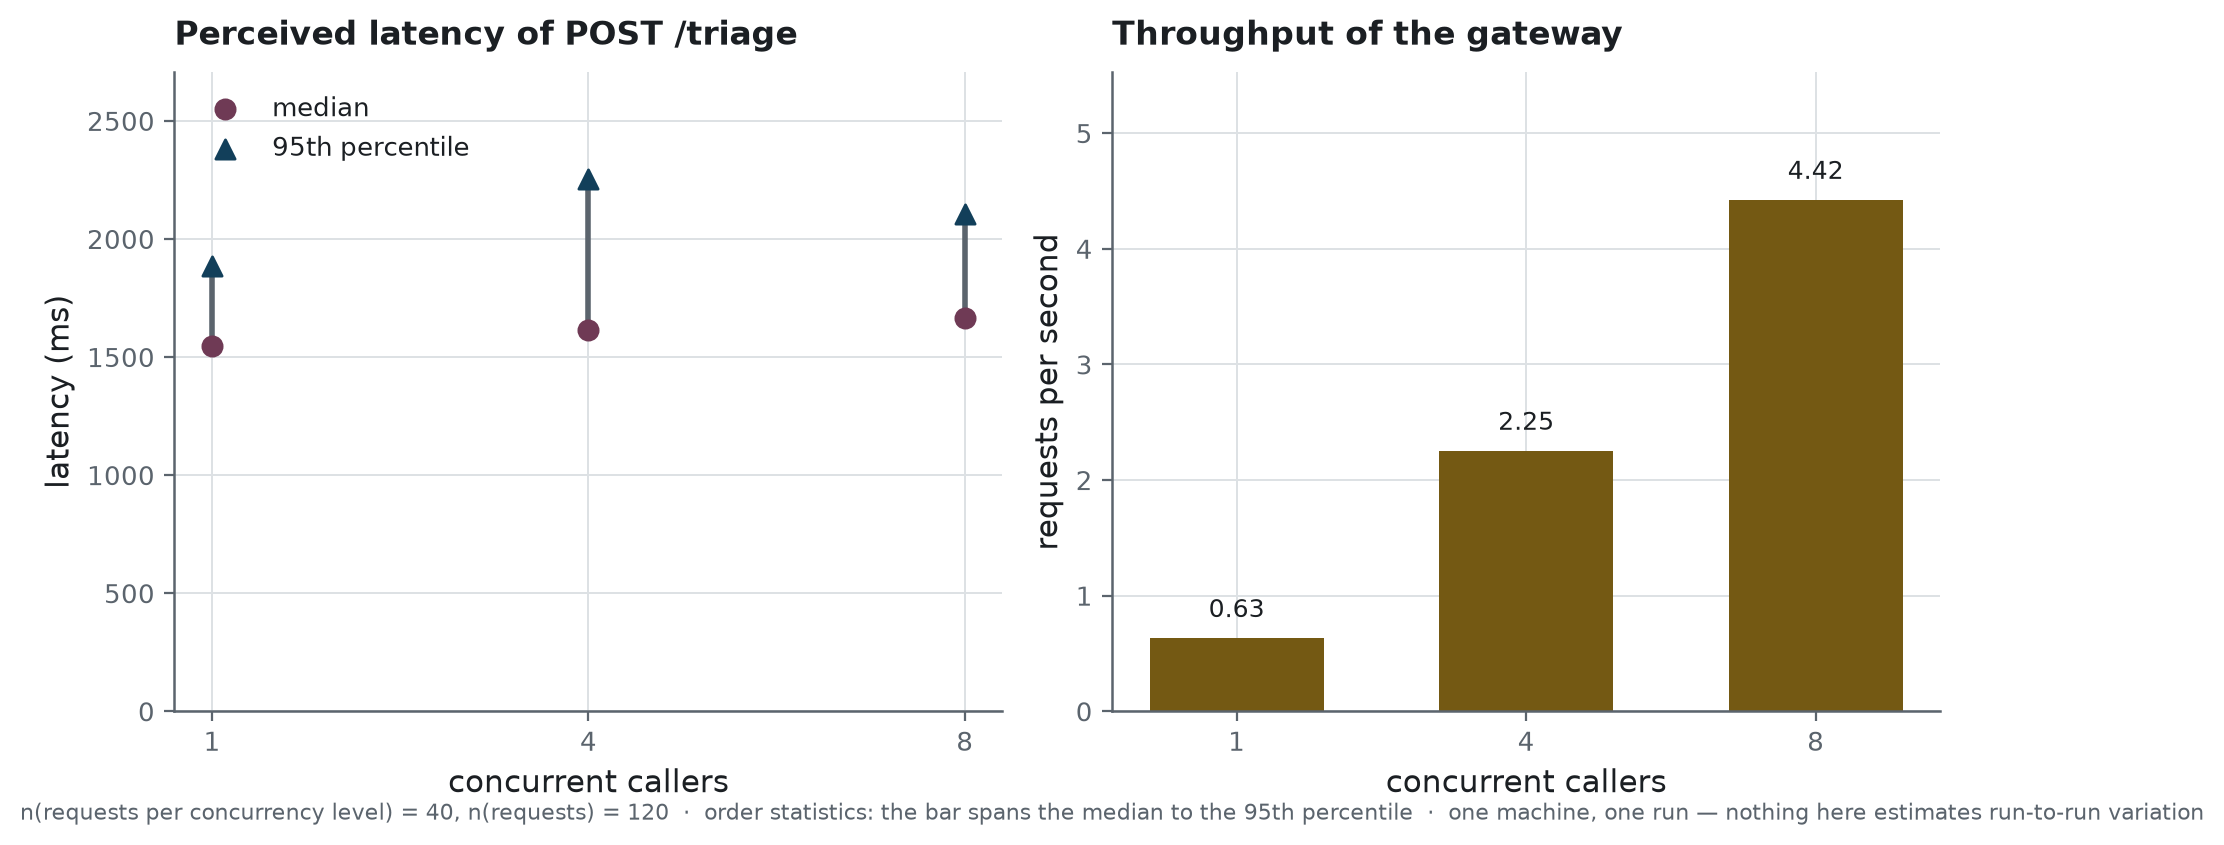

In [13]:
from IPython.display import Image

figure = PATHS.figures / "endpoint_latency.png"
if figure.exists():
    display(Image(str(figure)))

Latencies measured with the development engine are not comparable, and must never be reported
as the endpoint's.

## Where that leaves the service

- The questionnaire **follows the complaint** and stops as soon as a vital sign appears; the
  summary turns every answer into a sentence.
- The triage reply exposes the level, its justification, what to do next, **and the explicit
  rule's verdict**: the disagreement is visible.
- Access is protected by a mandatory key, compared in constant time, with a per-caller quota.
- Every interaction is traced, **masked by the audit module itself**, with the model actually
  loaded.
- The deployment separates the gateway from the model, each updating without the other.

> **What this notebook is.** A demonstration. The triage levels rest on a catalogue
> written for the project and never reviewed by a clinician, and the service is built to sit
> beside a human who decides. Anyone facing a real distress calls the emergency number first.